### Phase 3: EDA

In [1]:

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# seting visual style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [2]:
df_clean = pd.read_parquet('../final_datasets/clean_datasets/1_data_preparation_dataset.parquet')
df_clean.shape

(12112, 54)

In [3]:
df_clean.info()

<class 'pandas.DataFrame'>
MultiIndex: 12112 entries, (np.int64(1991), 'AX010') to (np.int64(2019), 'UNNAMED 25953')
Data columns (total 54 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   area_change           12112 non-null  float64
 1   elevation_change      12112 non-null  float64
 2   elevation_change_unc  12112 non-null  float64
 3   cenlon                12112 non-null  float64
 4   cenlat                12112 non-null  float64
 5   area_km2              12112 non-null  float64
 6   surge_type            12112 non-null  int64  
 7   zmin_m                12112 non-null  float64
 8   zmax_m                12112 non-null  float64
 9   zmed_m                12112 non-null  float64
 10  zmean_m               12112 non-null  float64
 11  slope_deg             12112 non-null  float64
 12  aspect_deg            12112 non-null  float64
 13  aspect_sec            12112 non-null  int64  
 14  lmax_m                12112 n

In [4]:
df_clean.head()

area_change  elevation_change  elevation_change_unc  \
year glacier_name                                                        
1991 AX010            568000.0            -8.689                  4.79   
1996 AX010            495000.0            -5.500                  4.79   
1999 AX010            450000.0            -2.470                  4.79   
2002 LHOTSE NUP       375000.0            -2.220                  4.79   
     NUPTSE           300000.0            -1.970                  4.79   

                      cenlon     cenlat  area_km2  surge_type     zmin_m  \
year glacier_name                                                          
1991 AX010         86.555703  27.715657  0.426034           0  4977.4860   
1996 AX010         86.555703  27.715657  0.426034           0  4977.4860   
1999 AX010         86.555703  27.715657  0.426034           0  4977.4860   
2002 LHOTSE NUP    86.890141  27.936466  2.351926           0  4963.2207   
     NUPTSE        86.861770  27.938681  2.351926           0  4973.5070   

                        zmax_m     zmed_m  ...          strd        ro  \
year glacier_name                          ...                           
1991 AX010         5326.812500  5221.8740  ...  2.314026e+07  0.003685   
1996 AX010         5326.812500  5221.8740  ...  2.301200e+07  0.003965   
1999 AX010         5326.812500  5221.8740  ...  2.367911e+07  0.004271   
2002 LHOTSE NUP    7105.239513  5261.5150  ...  1.938723e+07  0.001766   
     NUPTSE        5957.843300  5359.0513  ...  1.938723e+07  0.001766   

                         es       sro         e       u10       v10  \
year glacier_name                                                     
1991 AX010        -0.000035  0.002045 -0.001696  0.223243 -0.138062   
1996 AX010        -0.000023  0.002109 -0.001571  0.182166 -0.207591   
1999 AX010        -0.000011  0.002437 -0.001723  0.200245 -0.033395   
2002 LHOTSE NUP   -0.000061  0.000944 -0.000632  0.487552  0.008241   
     NUPTSE       -0.000061  0.000944 -0.000632  0.487552  0.008241   

                             sp        tp  actual_mass_change  
year glacier_name                                              
1991 AX010         63915.844667  0.005390          -4193900.0  
1996 AX010         63915.595917  0.005374          -2312000.0  
1999 AX010         63936.862250  0.006063           -943500.0  
2002 LHOTSE NUP    53253.895667  0.003240         -15300000.0  
     NUPTSE        53253.895667  0.003240         -36720000.0  

[5 rows x 54 columns]

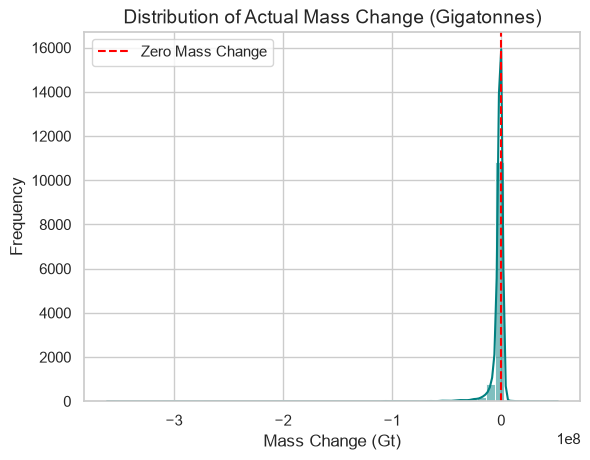

In [5]:
# distribution of the target variable
sns.histplot(
    x=df_clean["actual_mass_change"],
    bins=50,
    kde=True,
    color="teal"
)

plt.title('Distribution of Actual Mass Change (Gigatonnes)', fontsize=14)
plt.xlabel('Mass Change (Gt)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# vertical line at 0 to clearly show accumulation vs ablation (melt)
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Mass Change')
plt.legend()

plt.show()

Sligt glacier accumulation (mass gain) but mild and moderate to glacier ablation (mass loss)

In [6]:
df_map = df_clean.reset_index()


In [9]:


# Create the offline geometric scatter plot
fig = px.scatter_geo(
    df_map, 
    lat="cenlat", 
    lon="cenlon", 
    color="actual_mass_change",
    size="area_km2",
    hover_name="glacier_name",          
    hover_data=["year", "actual_mass_change"], 
    color_continuous_scale=px.colors.sequential.Magma,
    title="Offline Geospatial Map of Glacier Mass Change",
    size_max=8,                         
    
)

# Automatically zoom into the data points and add basic country borders
fig.update_geos(
    fitbounds="locations", 
    showcountries=True, 
    countrycolor="LightGrey",
    showland=True,
    landcolor="White"
)

# Reduce the margins so the map fills the output cell
fig.update_layout(margin={"r":0,"t":40,"l":0,"b":0})

fig.show()

In [8]:


# Calculate the exact center coordinates of your dataset
center_lat = df_map['cenlat'].mean()
center_lon = df_map['cenlon'].mean()

# Define a custom color sequence: Black/Purple (extreme loss) -> Red (loss) -> Green (gain)
custom_color_scale = [
    [0.0, "black"],   # Maximum mass loss
    [0.25, "purple"], # Severe mass loss
    [0.48, "red"],    # Moderate mass loss
    [0.5, "pink"],# Zero change
    [1.0, "green"]    # Mass gain
]

# Create the interactive OpenStreetMap scatter plot
fig = px.scatter_map(
    df_map, 
    lat="cenlat", 
    lon="cenlon", 
    color="actual_mass_change",
    size="area_km2",
    hover_name="glacier_name",          
    hover_data=["year", "actual_mass_change"], 
    color_continuous_scale=custom_color_scale,
    size_max=8,                         
    zoom=5,                           
    center={"lat": center_lat, "lon": center_lon}, 
    map_style="open-street-map",        
    title="OpenStreetMap: Glacier Mass Change "
)

# Reduce the margins so the map fills the output cell
fig.update_layout(margin={"r":0,"t":40,"l":0,"b":0})

fig.show()